# Zadanie 1 — PenDigits

**Cel:** poznaj numeryczny zbiór danych, porównaj kilka uzasadnionych metod klasyfikacji statystycznej i uczenia maszynowego oraz oceń, czy większa złożoność modelu daje istotną korzyść.

In [88]:
!pip install matplotlib numpy pandas seaborn huggingface_hub scikit-learn xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 7.0 MB/s  0:00:00 eta 0:00:01

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [ ]:
# Proponowane importy — możesz je zmienić lub rozszerzyć.
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from time import perf_counter
from xgboost import XGBClassifier
from huggingface_hub import hf_hub_download
import sklearn
from sklearn.metrics import classification_report, confusion_matrix, precision_score, recall_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

sklearn.set_config(transform_output="pandas")

In [3]:
# Pobranie niezmienionego archiwum z oficjalnymi podziałami train/test.
DATA_DIR = Path("data/zadanie-1")
DATA_DIR.mkdir(parents=True, exist_ok=True)

archive_path = hf_hub_download(
    repo_id="AI-MED-AGH/Recruitment-Task-1",
    filename="original/pen+based+recognition+of+handwritten+digits.zip",
    repo_type="dataset",
    local_dir=DATA_DIR,
)
with ZipFile(archive_path) as archive:
    archive.extractall(DATA_DIR / "pendigits")

print(f"Dane zapisano w: {DATA_DIR / 'pendigits'}")

Dane zapisano w: data/zadanie-1/pendigits


In [47]:
def plot_confusion_matrix(cm):  
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title('Confusion Matrix')
    plt.xlabel('Przewidziana klasa')
    plt.ylabel('Prawdziwa klasa')
    plt.show()

## A — Poznanie i przygotowanie danych



In [113]:
column_names = [f"{coord}{i}" for i in range(1, 9) for coord in ('x', 'y')] + ['digit']
df_train = pd.read_csv("data/zadanie-1/pendigits/pendigits-tra.csv", header=None, names=column_names)
df_test = pd.read_csv("data/zadanie-1/pendigits/pendigits-tes.csv", header=None, names=column_names)
df_train.info()
df_train.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 7494 entries, 0 to 7493
Data columns (total 17 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   x1      7494 non-null   int64
 1   y1      7494 non-null   int64
 2   x2      7494 non-null   int64
 3   y2      7494 non-null   int64
 4   x3      7494 non-null   int64
 5   y3      7494 non-null   int64
 6   x4      7494 non-null   int64
 7   y4      7494 non-null   int64
 8   x5      7494 non-null   int64
 9   y5      7494 non-null   int64
 10  x6      7494 non-null   int64
 11  y6      7494 non-null   int64
 12  x7      7494 non-null   int64
 13  y7      7494 non-null   int64
 14  x8      7494 non-null   int64
 15  y8      7494 non-null   int64
 16  digit   7494 non-null   int64
dtypes: int64(17)
memory usage: 995.4 KB


,count,mean,std,min,25%,50%,75%,max
x1,7494.0,37.384307,33.322024,0.0,5.0,31.0,61.0,100.0
y1,7494.0,84.679343,16.848420,0.0,76.0,89.0,100.0,100.0
x2,7494.0,40.005604,26.256025,0.0,20.0,39.0,58.0,100.0
y2,7494.0,82.889512,19.638582,0.0,70.0,89.0,100.0,100.0
x3,7494.0,50.878303,34.927201,0.0,17.0,56.0,81.0,100.0
y3,7494.0,65.044436,27.377341,0.0,48.0,71.0,86.0,100.0
x4,7494.0,51.471844,30.680075,0.0,28.0,54.0,75.0,100.0
y4,7494.0,44.599680,30.659478,0.0,22.0,42.0,65.0,100.0
x5,7494.0,57.129971,33.680340,0.0,30.0,60.0,88.0,100.0
y5,7494.0,34.069122,27.459989,0.0,7.0,33.0,55.0,100.0


Text(0, 0.5, 'Liczba wystąpień')

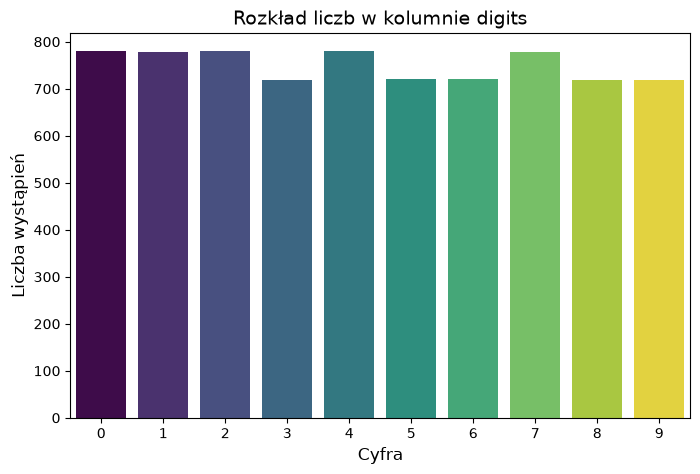

In [114]:
plt.figure(figsize=(8,5))
sns.countplot(data=df_train, x='digit', palette='viridis', hue='digit', legend=False)
plt.title('Rozkład liczb w kolumnie digits', fontsize=14)
plt.xlabel('Cyfra', fontsize=12)
plt.ylabel('Liczba wystąpień', fontsize=12)

Zbiór danych skałda się jedynie z wartości numerycznych, nie ma brakujących wartości i outlierów - wszystkie współrzędne przyjmują wartości z zakresu 0...100. Rozkład klas jest symetryczny.
Korzystam ze skalera, by ujednolicić wariancję i zapewnić stabilność numeryczną modelom wrażliwym na skalę.

In [115]:
y_train = df_train.pop('digit')
X_train =  df_train
y_test = df_test.pop('digit')
X_test = df_test

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
results = []


## B — Modelowanie



**Regresja multinomialna** 

/Users/julia/Studia/IT/Rekrutacja-AI-Med/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/julia/Studia/IT/Rekrutacja-AI-Med/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Users/julia/Studia/IT/Rekrutacja-AI-Med/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its d

Najlepsze hiperparametry: {'C': 50.0, 'penalty': 'l1'}
              precision    recall  f1-score   support

           0       0.97      0.90      0.93       363
           1       0.86      0.90      0.88       364
           2       0.95      0.98      0.96       364
           3       0.97      0.99      0.98       336
           4       0.94      0.96      0.95       364
           5       0.85      0.95      0.90       335
           6       0.97      0.96      0.97       336
           7       0.98      0.83      0.90       364
           8       0.84      0.88      0.86       336
           9       0.97      0.93      0.95       336

    accuracy                           0.93      3498
   macro avg       0.93      0.93      0.93      3498
weighted avg       0.93      0.93      0.93      3498



/Users/julia/Studia/IT/Rekrutacja-AI-Med/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


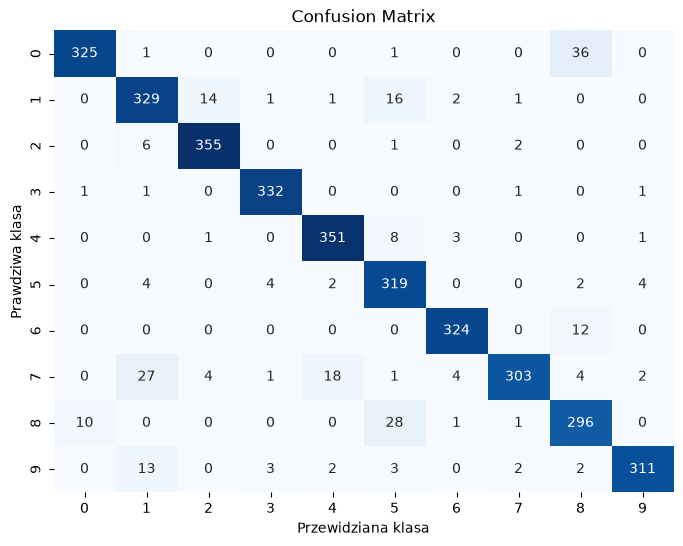

In [116]:
log_reg = LogisticRegression(solver='saga', max_iter=2000)
log_reg.fit(X_train,y_train)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
param_grid_lr = {
    'C': [0.001, 0.01, 0.1, 1.0, 10.0, 50.0, 100.0],
    'penalty': ['l1', 'l2']
}

grid_search_lr = GridSearchCV(
    estimator=log_reg,
    param_grid=param_grid_lr,
    cv=skf,
    scoring='accuracy',
    n_jobs=-1  
)

grid_search_lr.fit(X_train, y_train)
print("Najlepsze hiperparametry:", grid_search_lr.best_params_)


time_start_train_lr = perf_counter()
best_log_reg = LogisticRegression(**grid_search_lr.best_params_, solver='saga', max_iter=2000).fit(X_train, y_train)
time_end_train_lr = perf_counter()

time_start_pred_lr = perf_counter()
y_pred_log_reg = best_log_reg.predict(X_test)
time_end_pred_lr = perf_counter()

print(classification_report(y_test, y_pred_log_reg))
cm_lr = confusion_matrix(y_test, y_pred_log_reg)
plot_confusion_matrix(cm_lr)

accuracy_lr = np.sum(np.diagonal(cm_lr)) / np.sum(cm_lr)
precision_lr = precision_score(y_test, y_pred_log_reg, average='macro')
recall_lr = recall_score(y_test, y_pred_log_reg, average='macro')


results.append({
    "Model": "Logistic Regression",
    "Train Time (s)": time_end_train_lr - time_start_train_lr,
    "Inference Time (s)": time_end_pred_lr - time_start_pred_lr,
    "Accuracy": accuracy_lr,
    "Precision": precision_lr,
    "Recall": recall_lr
})

**Decision tree**

Najlepsze hiperparametry: {'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 2}
              precision    recall  f1-score   support

           0       0.97      0.94      0.96       363
           1       0.85      0.88      0.86       364
           2       0.87      0.94      0.90       364
           3       0.88      0.93      0.90       336
           4       0.92      0.96      0.94       364
           5       0.95      0.84      0.89       335
           6       0.96      0.93      0.95       336
           7       0.93      0.85      0.89       364
           8       0.91      0.93      0.92       336
           9       0.91      0.93      0.92       336

    accuracy                           0.91      3498
   macro avg       0.92      0.91      0.91      3498
weighted avg       0.92      0.91      0.91      3498



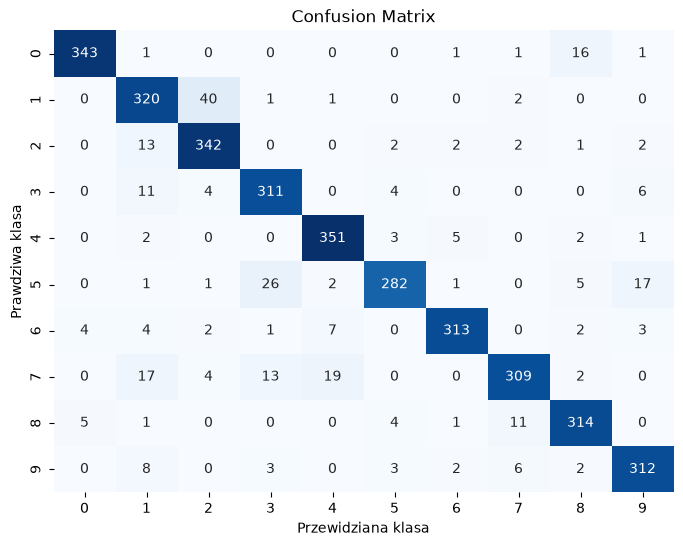

0.9139508290451687


In [117]:
dec_tree = DecisionTreeClassifier()

param_grid_dt = {
    'max_depth': [None, 5, 10, 15, 20],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 5, 10]
}

grid_search_dt = GridSearchCV(
    estimator=dec_tree,
    param_grid=param_grid_dt,
    cv=skf,
    scoring='accuracy',
    n_jobs=-1  
)

grid_search_dt.fit(X_train, y_train)
print("Najlepsze hiperparametry:", grid_search_dt.best_params_)
time_start_train_dt = perf_counter()
best_dec_tree = DecisionTreeClassifier(**grid_search_dt.best_params_).fit(X_train, y_train)
time_end_train_dt = perf_counter()

time_start_pred_dt = perf_counter()
y_pred_dec_tree = best_dec_tree.predict(X_test)
time_end_pred_dt = perf_counter()

print(classification_report(y_test, y_pred_dec_tree))
cm_dt = confusion_matrix(y_test, y_pred_dec_tree)
plot_confusion_matrix(cm_dt)

accuracy_dt = np.sum(np.diagonal(cm_dt)) / np.sum(cm_dt)
precision_dt = precision_score(y_test, y_pred_dec_tree, average='macro')
recall_dt = recall_score(y_test, y_pred_dec_tree, average='macro')
print(accuracy_dt)


results.append({
    "Model": "Decision Tree",
    "Train Time (s)": time_end_train_dt - time_start_train_dt,
    "Inference Time (s)": time_end_pred_dt - time_start_pred_dt,
    "Accuracy": accuracy_dt,
    "Precision": precision_dt,
    "Recall": recall_dt
})

**Random forest**

Najlepsze hiperparametry: {'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 6, 'max_depth': 20}
              precision    recall  f1-score   support

           0       0.99      0.96      0.97       363
           1       0.89      0.91      0.90       364
           2       0.92      0.99      0.95       364
           3       0.97      0.99      0.98       336
           4       1.00      1.00      1.00       364
           5       1.00      0.94      0.97       335
           6       1.00      1.00      1.00       336
           7       0.99      0.90      0.94       364
           8       0.95      0.99      0.97       336
           9       0.95      0.98      0.96       336

    accuracy                           0.96      3498
   macro avg       0.97      0.96      0.96      3498
weighted avg       0.97      0.96      0.96      3498



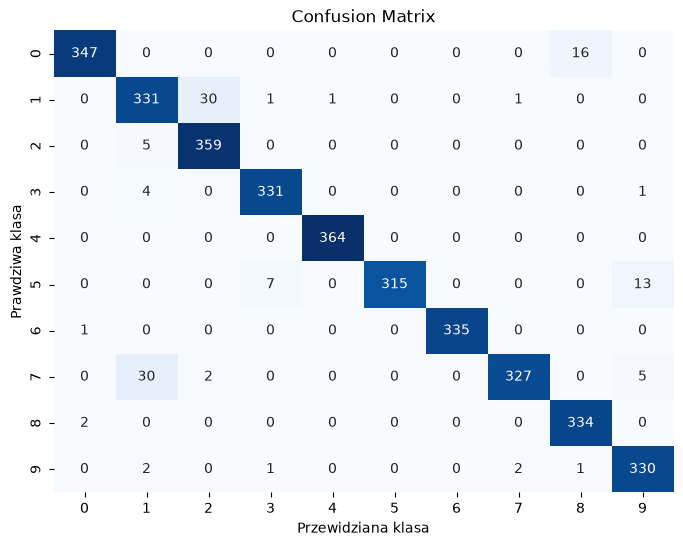

0.9642652944539737


In [118]:
rand_forest = RandomForestClassifier()

param_rand_rf = {
    'max_depth': [None, 5, 10, 15, 20],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 5, 10],
    'n_estimators': [500],
    'max_features': [2,4,6,8]
}

rand_search_rf = RandomizedSearchCV(
    estimator=rand_forest,
    param_distributions=param_rand_rf,
    cv=skf,
    scoring='accuracy',
    n_jobs=-1,
    n_iter=20  
)

rand_search_rf.fit(X_train, y_train)
print("Najlepsze hiperparametry:", rand_search_rf.best_params_)
time_start_train_rf = perf_counter()
best_rand_forest = RandomForestClassifier(**rand_search_rf.best_params_).fit(X_train, y_train)
time_end_train_rf = perf_counter()

time_start_pred_rf = perf_counter()
y_pred_rand_forest = best_rand_forest.predict(X_test)
time_end_pred_rf = perf_counter()

print(classification_report(y_test, y_pred_rand_forest))
cm_rf = confusion_matrix(y_test, y_pred_rand_forest)
plot_confusion_matrix(cm_rf)

accuracy_rf = np.sum(np.diagonal(cm_rf)) / np.sum(cm_rf)
precision_rf = precision_score(y_test, y_pred_rand_forest, average='macro')
recall_rf = recall_score(y_test, y_pred_rand_forest, average='macro')
print(accuracy_rf)

results.append({
    "Model": "Random Forest",
    "Train Time (s)": time_end_train_rf - time_start_train_rf,
    "Inference Time (s)": time_end_pred_rf - time_start_pred_rf,
    "Accuracy": accuracy_rf,
    "Precision": precision_rf,
    "Recall": recall_rf
})

**K-Nearest Neighbors**

Najlepsze hiperparametry: {'metric': 'manhattan', 'n_neighbors': 3}
              precision    recall  f1-score   support

           0       1.00      0.96      0.98       363
           1       0.95      0.96      0.95       364
           2       0.96      0.99      0.98       364
           3       0.96      0.99      0.98       336
           4       0.99      0.98      0.98       364
           5       0.97      0.97      0.97       335
           6       0.97      1.00      0.98       336
           7       0.98      0.96      0.97       364
           8       0.99      1.00      0.99       336
           9       0.98      0.95      0.97       336

    accuracy                           0.98      3498
   macro avg       0.98      0.98      0.98      3498
weighted avg       0.98      0.98      0.98      3498



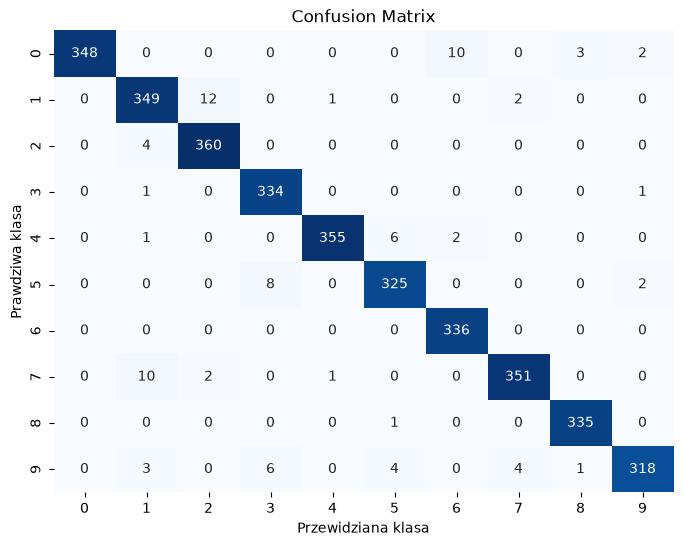

0.9751286449399656


In [119]:
knn = KNeighborsClassifier()

param_grid_knn = {
    'n_neighbors': [3, 5, 10, 15, 20, 25, 30],
    'metric': ['euclidean', 'manhattan'],
}

grid_search_knn = GridSearchCV(
    estimator=knn,
    param_grid=param_grid_knn,
    cv=skf,
    scoring='accuracy',
    n_jobs=-1  
)

grid_search_knn.fit(X_train, y_train)
print("Najlepsze hiperparametry:", grid_search_knn.best_params_)
time_start_train_knn = perf_counter()
best_knn = KNeighborsClassifier(**grid_search_knn.best_params_).fit(X_train, y_train)
time_end_train_knn = perf_counter()

time_start_pred_knn = perf_counter()
y_pred_knn = best_knn.predict(X_test)
time_end_pred_knn = perf_counter()

print(classification_report(y_test, y_pred_knn))
cm_knn = confusion_matrix(y_test, y_pred_knn)
plot_confusion_matrix(cm_knn)

accuracy_knn = np.sum(np.diagonal(cm_knn)) / np.sum(cm_knn)
precision_knn = precision_score(y_test, y_pred_knn, average='macro')
recall_knn = recall_score(y_test, y_pred_knn, average='macro')
print(accuracy_knn)

results.append({
    "Model": "K Nearest Neighbors",
    "Train Time (s)": time_end_train_knn - time_start_train_knn,
    "Inference Time (s)": time_end_pred_knn - time_start_pred_knn,
    "Accuracy": accuracy_knn,
    "Precision": precision_knn,
    "Recall": recall_knn
})

**Gradient boosting**

Najlepsze hiperparametry: {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 500, 'subsample': 0.8}
              precision    recall  f1-score   support

           0       0.99      0.94      0.97       363
           1       0.91      0.94      0.93       364
           2       0.94      0.99      0.97       364
           3       0.97      0.99      0.98       336
           4       0.98      0.99      0.99       364
           5       0.99      0.96      0.97       335
           6       0.99      0.99      0.99       336
           7       0.98      0.89      0.94       364
           8       0.93      0.99      0.96       336
           9       0.96      0.96      0.96       336

    accuracy                           0.97      3498
   macro avg       0.97      0.97      0.97      3498
weighted avg       0.97      0.97      0.97      3498



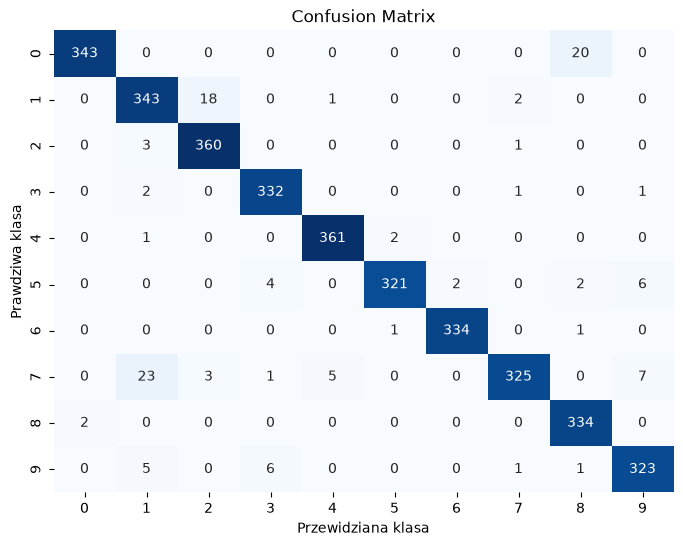

0.9651229273870783


In [120]:
grad_boost = XGBClassifier()

param_grid_gb = {
    'max_depth': [2, 4, 8],
    'n_estimators': [500],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.8, 0.9]
}

grid_search_gb = GridSearchCV(
    estimator=grad_boost,
    param_grid=param_grid_gb,
    cv=skf,
    scoring='accuracy',
    n_jobs=-1,
)

grid_search_gb.fit(X_train, y_train)
print("Najlepsze hiperparametry:", grid_search_gb.best_params_)
time_start_train_gb = perf_counter()
best_grad_boost = XGBClassifier(**grid_search_gb.best_params_).fit(X_train, y_train)
time_end_train_gb = perf_counter()

time_start_pred_gb = perf_counter()
y_pred_grad_boost = best_grad_boost.predict(X_test)
time_end_pred_gb = perf_counter()

print(classification_report(y_test, y_pred_grad_boost))
cm_gb = confusion_matrix(y_test, y_pred_grad_boost)
plot_confusion_matrix(cm_gb)

accuracy_gb = np.sum(np.diagonal(cm_gb)) / np.sum(cm_gb)
precision_gb = precision_score(y_test, y_pred_grad_boost, average='macro')
recall_gb = recall_score(y_test, y_pred_grad_boost, average='macro')
print(accuracy_gb)

results.append({
    "Model": "XGB",
    "Train Time (s)": time_end_train_gb - time_start_train_gb,
    "Inference Time (s)": time_end_pred_gb - time_start_pred_gb,
    "Accuracy": accuracy_gb,
    "Precision": precision_gb,
    "Recall": recall_gb
})

## C — Porównanie i wnioski


In [121]:
df_results = pd.DataFrame(results)
print(df_results.to_string(index=False))

              Model  Train Time (s)  Inference Time (s)  Accuracy  Precision   Recall
Logistic Regression        5.362467            0.001007  0.927673   0.930155 0.928231
      Decision Tree        0.025159            0.000574  0.913951   0.915895 0.913880
      Random Forest        3.410811            0.083227  0.964265   0.965820 0.964851
K Nearest Neighbors        0.000909            0.032858  0.975129   0.975380 0.975369
                XGB        4.479635            0.012711  0.965123   0.966154 0.965655


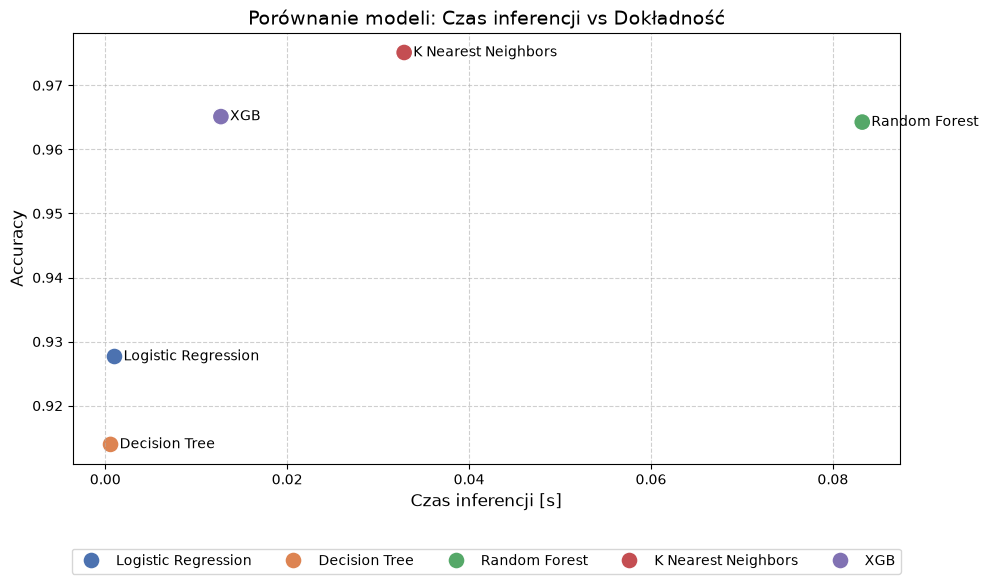

In [130]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_results,
    x="Inference Time (s)",
    y="Accuracy",
    hue="Model",
    s=150,
    palette="deep",
)

plt.title("Porównanie modeli: Czas inferencji vs Dokładność", fontsize=14)
plt.xlabel("Czas inferencji [s]", fontsize=12)
plt.ylabel("Accuracy", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)

for i, row in df_results.iterrows():
  plt.text(
      row["Inference Time (s)"] + 0.001,
      row["Accuracy"],
      row["Model"],
      fontsize=10,
      verticalalignment="center",
  )

plt.legend(bbox_to_anchor=(0.5, -0.18), loc="upper center", ncol=5, frameon=True)

plt.tight_layout()
plt.show()

Najwyższą dokładnością charakteryzuje się model KNN, jednak okupuje to stosunkowo długim czasem inferencji. Ponieważ jako algorytm typu lazy learner musi on stale przechowywać w pamięci cały zbiór treningowy, wraz ze wzrostem ilości danych staje się on coraz mniej opłacalny. Z kolei modele bazowe – drzewo decyzyjne oraz regresja logistyczna – są bardzo szybkie w treningu i predykcji, ale ich skuteczność predykcyjna jest niższa.

Optymalnym kompromisem dla tego zadania okazuje się XGBoost (oparty na boostingu gradientowym). Zapewnia on znakomity balans między wysoką jakością predykcji a błyskawicznym czasem odpowiedzi, a jednocześnie doskonale skaluje się do większych zbiorów danych.

### Źródła

* Materiały i wykłady z przedmiotu **Podstawy sztucznej inteligencji** – prowadzący: mgr inż. Jakub Adamczyk (AGH).

### Narzędzia AI

* **Gemini** – debugowanie kodu w Pythonie, przeszukiwanie dokumentacji technicznej oraz analizę hiperparametrów modeli.